# Fusion Equilibrium Challenge — Challenge-2 (MAST) Conv Model Training

Trains `Ch2PhysConvNet` -- a conv net on a 5-channel **image** representation of each
DIII-D shot, instead of `05_train_challenge2.py`'s flat 7-feature RidgeCV. That model has
run out of road: in-sample flux R2 ~0.06-0.08, and the real Codabench score for MAST sits
at `S_MAST ≈ 0.057` with the Consistency term pinned at exactly `0.0` -- a linear model
through a 30-component PCA basis has no way to represent 2-D spatial structure at all.

**The 5 input channels** (`fec_common/ch2_features.py`), each a 65×65 map, built
identically for DIII-D and MAST despite their very different coil counts (19 vs 812) and
Thomson layouts:

0. **`vacuum_psi`** -- the coil-only flux map from a real Green's-function/Biot-Savart
   calculation (`fec_common/vacuum_field.py`) on each shot's own coil geometry
   (`coil_R`/`coil_Z`) and currents. This is the one genuinely shared-physics channel:
   *same formula*, each machine's own geometry, zero MAST-specific fitting. (The starter
   kit's own README notes this reaches R² ≈ 0.94 fitting psi *outside the plasma
   envelope* -- a full-grid check during development showed R²≈0.01, which is expected:
   the plasma's own current dominates the interior, that's exactly the residual this
   model has to learn.)
1-2. **R_norm / Z_norm** -- CoordConv position channels, this shot's own grid min-max
   normalized to [-1, 1].
3. **`core_pressure`** -- core-Thomson Te·ne, Gaussian-smoothed from each channel's own
   radius onto the grid (`data_fixes.align_mast_thomson_core`, which also handles
   DIII-D unchanged).
4. **`Ip_broadcast`** -- plasma current, z-scored with a constant fit on DIII-D only,
   broadcast across the grid.

**Target**: `psi / sigma_physics` -- a sigma-normalized (but NOT mean-subtracted) flux map.
The network predicts only a scale-free *shape*; absolute amplitude comes from a physics
law instead of a learned head:

    sigma(t) = 6.003e-5 * |Ip(t)[kA]| * R0[m]        (fit on DIII-D: R2 = 0.915, corr +0.96)

with `Ip` and `R0` taken from **each machine's own inputs** (`R0` = Thomson-core chord-radii
midpoint, an input on both machines). No MAST labels or MAST-derived statistics anywhere
(rule 3).

**Why this replaced the previous design.** The first version of this model learned a
log-amplitude head and scored `S_MAST = 0.002` -- *worse* than the RidgeCV baseline's
0.0575. Diagnosing it turned up three real bugs, all now fixed in `fec_common`:

1. **`efit_psirz` is stored `[iZ, iR]`, not `[iR, iZ]`.** The Green's-function basis and the
   CoordConv/pressure channels were all built transposed against the target. Verified against
   the shipped `efit_r_axis`/`efit_z_axis`: `argmin(psi)` lands 0.017 m from the true magnetic
   axis under `[iZ, iR]` vs 0.105 m transposed. A 65x65 grid raises no shape error, and
   DIII-D's near-up-down-symmetric equilibria make a transposed map look only mildly wrong,
   so this survives any full-grid fitted-scale check -- it has to be tested against the axis.
2. **MAST P-coil turns were double-counted.** `magnetics_p{2-6}{l,u}_current` is already
   turns-folded ampere-turns, but the basis summed the Green's function over all 20/8/23/23/4
   conductor-element rows sharing each column -- an 8-23x overcount. (The 656-element solenoid
   is the opposite case, a true per-turn current, and is still correctly summed.)
3. **The learned amplitude head could not transfer.** It conditioned on `log(vacuum_rms)`,
   whose MAST distribution is out-of-sample, and overshot ~7x (predicted max|psi| 1.12 Wb vs a
   physics-implied 0.156 Wb) -- matching the `k ~ 6` overshoot implied by the scored
   `R2_psi = -25.9`. Note a *constant* prediction scores `R2 = 0`, so that head was strictly
   worse than predicting nothing. It is gone; amplitude is now dimensional analysis.

**Amplitude shrink.** With `pred = beta*sigma*shape` and shape-correlation `rho`,
`R2 = 2*beta*rho - beta^2`, and the scorer clamps negative terms to zero. `beta = 0.5`
(`CH2_AMP_SHRINK`) stays positive for every `rho > 0.25` and is near-optimal over
`rho` in [0.5, 0.9], whereas `beta = 1` scores 0 unless `rho > 0.5`. Overshoot is
unbounded-bad, undershoot is capped -- so shrink deliberately.

**Memory**: each frame's image stack is ~5x heavier than the plain conv decoder's
psi-only target (42 KB/frame at float16 vs ~8.5 KB). This notebook defaults to 1500 train
/ 300 val shots (~12-15 GB on a 23 GB GPU) rather than the full 7041-shot split --
raise `n_shots_train`/`n_shots_val` in the training cell if your run has headroom.

Needs the Drive-synced `code/run/` and `code/artifacts/features/` (from local `00`/`01`)
to already exist -- this does NOT re-extract features, only builds new image inputs +
trains a new model against the 01 cache's `split.json` (for the train/val shot ids).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
# torch ships with Colab already -- nothing to pip install for this notebook.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import sys
from pathlib import Path

FOLDER_NAME = "EXPERIMENTS/FEC_NeurIPS/code"
CODE_DIR = Path("/content/drive/MyDrive") / FOLDER_NAME
RUN_DIR = CODE_DIR / "run"
ARTIFACTS_DIR = CODE_DIR / "artifacts"

assert RUN_DIR.exists(), f"{RUN_DIR} not found -- check Drive sync and FOLDER_NAME above"
sys.path.insert(0, str(RUN_DIR))

from fec_common.config import ensure_starter, log  # noqa: E402

ensure_starter()
import torch
assert torch.cuda.is_available(), "No GPU attached -- Runtime > Change runtime type > GPU"
print("CUDA:", torch.cuda.get_device_name(0),
     f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


CUDA: NVIDIA A100-SXM4-40GB 42.4 GB


## 0b. Sanity-check the 01 cache + new modules synced correctly

Insync can lag on large binary files even after a small `.py` edit has already synced.
Catch that here, with a clear message, instead of a confusing traceback three calls deep.

In [3]:
import json

_split = json.load(open(ARTIFACTS_DIR / "features" / "split.json"))
print(f"split.json: {len(_split['train'])} train / {len(_split['val'])} val shot ids")

import fec_common.ch2_features as _cf
import fec_common.vacuum_field as _vf
import fec_common.conv_decoder as _cd
import fec_common.train_ch2_conv_colab as _m

assert hasattr(_cd, "Ch2PhysConvNet"), (
    "conv_decoder.py is missing Ch2PhysConvNet -- Drive sync hasn't caught up yet. Wait a "
    "bit and re-run this cell (or Runtime > Restart runtime if it still fails after waiting)."
)
print("ch2_features / vacuum_field / Ch2PhysConvNet / train_ch2_conv_colab all present.")
del _split, _cf, _vf, _cd, _m


split.json: 4929 train / 704 val shot ids
ch2_features / vacuum_field / Ch2PhysConvNet / train_ch2_conv_colab all present.


## 0c. Smoke-test the model shapes (CPU, no data)

Catches a shape/dtype bug in under a second, before a multi-hour data load.

In [4]:
import torch as _torch
from fec_common.conv_decoder import Ch2PhysConvNet, ch2_loss
import fec_common.ch2_features as _CF

_m = Ch2PhysConvNet()
_images = _torch.randn(4, 5, 65, 65)
_aux = _torch.randn(4, 3)
_shape, _q95, _betan = _m(_images, _aux)          # no amplitude head any more
assert _shape.shape == (4, 65, 65), _shape.shape
_loss = ch2_loss(_shape, _shape.detach(), _q95, _q95.detach(), _betan, _betan.detach())
assert _torch.isfinite(_loss)
print(f"Ch2PhysConvNet OK -- {sum(p.numel() for p in _m.parameters()):,} params, "
     f"loss {_loss.item():.4f}")
print(f"sigma law C = {_CF.CH2_SIGMA_C:.4g}   amplitude shrink beta = {_CF.CH2_AMP_SHRINK}")
del _m, _images, _aux, _shape, _q95, _betan, _loss


Ch2PhysConvNet OK -- 470,467 params, loss 0.0000
sigma law C = 6.003e-05   amplitude shrink beta = 0.5


## 1. Train

Loads a subset of DIII-D train/val shots via the threaded parquet loader (16 workers),
builds the 5-channel image stack per shot, holds the whole (bounded) dataset resident on
the GPU (same strategy as `train_conv_decoder_colab.py`), and trains.
Checkpoints the best-val-loss model to `code/artifacts/models/ch2_conv.pt`, which
`predict.py`'s `Ch2TorchConvModel` picks up automatically (preferred over the `ch2.joblib`
RidgeCV fallback whenever `ch2_conv.pt` exists).

In [5]:
from fec_common.train_ch2_conv_colab import train

model, history, bundle = train(
    n_shots_train=1500, n_shots_val=300, epochs=20, batch_size=128,
    load_workers=16,
)
print({k: v for k, v in bundle.items() if k != "state_dict"})


[12:53:46] device: cuda (NVIDIA A100-SXM4-40GB, 42.4 GB)
[12:54:14] loading 1500 train shots + 300 val shots (19 coil columns)...


train shots:   0%|          | 0/1500 [00:00<?, ?shot/s]

val shots:   0%|          | 0/300 [00:00<?, ?shot/s]

[13:12:08]   333771 train frames / 68577 val frames  (1074s)
[13:12:12]   sigma_physics (train) median=0.1153 Wb  target psi/sigma std=1.962
[13:12:20]   val psi: mean=+0.0241 Wb  SS_tot=1.114e+07
[13:16:50]   epoch  1/20  train_loss 2.46673  val_loss 2.09263  shape_R2 0.6436  psi_R2 0.6557  psi_R2@b=0.5 0.5041  q95_R2 0.7061  betaN_R2 0.6545  (265s)
[13:21:11]   epoch  2/20  train_loss 2.04413  val_loss 1.86167  shape_R2 0.6823  psi_R2 0.7011  psi_R2@b=0.5 0.5182  q95_R2 0.8457  betaN_R2 0.8040  (261s)
[13:25:34]   epoch  3/20  train_loss 1.81034  val_loss 1.80774  shape_R2 0.6896  psi_R2 0.7135  psi_R2@b=0.5 0.5308  q95_R2 0.8667  betaN_R2 0.8492  (262s)
[13:29:56]   epoch  4/20  train_loss 1.64251  val_loss 1.64644  shape_R2 0.7177  psi_R2 0.7340  psi_R2@b=0.5 0.5413  q95_R2 0.9212  betaN_R2 0.8711  (263s)
[13:34:20]   epoch  5/20  train_loss 1.52835  val_loss 1.65532  shape_R2 0.7163  psi_R2 0.7111  psi_R2@b=0.5 0.5466  q95_R2 0.9248  betaN_R2 0.8269  (264s)
[13:38:43]   epoch  6/2

## 2. Plot loss and accuracy

**`psi_R2` is the number to watch** -- it is computed in real Wb (`sigma * shape_pred` vs
true psi, pooled) and is the in-domain analogue of the `R2_psi` the official scorer
reports, which carries 0.55 of the composite score. `psi_R2@b=0.5` is the same quantity
with the amplitude shrink actually used at submission time; on DIII-D (in-domain, high
`rho`) the shrink *costs* R2, so expect it to sit below `psi_R2` here -- that gap is the
insurance premium being paid for the zero-shot transfer.

`shape_R2` is on the sigma-normalized target, so it is not comparable to
`05_train_challenge2.py`'s PCA-coefficient "flux R2" on its different linear basis.

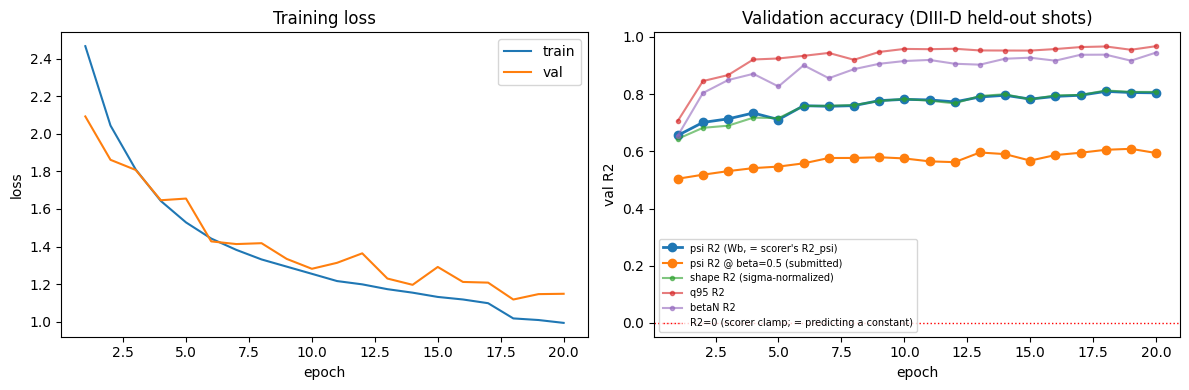

best epoch 19: psi_R2=0.8056  psi_R2@shrink=0.6088  shape_R2=0.8079
MAST reference: the scored baselines are S_MAST = 0.0575 (RidgeCV) and 0.002 (first conv attempt); both scored 0.0 on R2_psi, R2_qb and Consistency, i.e. every MAST point so far came from the D_LCFS term alone.


In [6]:
import matplotlib.pyplot as plt

epochs_ = [h["epoch"] for h in history]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_, [h["train_loss"] for h in history], label="train")
ax1.plot(epochs_, [h["val_loss"] for h in history], label="val")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend()
ax1.set_title("Training loss")

ax2.plot(epochs_, [h["psi_r2"] for h in history], label="psi R2 (Wb, = scorer's R2_psi)",
         marker="o", linewidth=2)
ax2.plot(epochs_, [h["psi_r2_shrunk"] for h in history], label="psi R2 @ beta=0.5 (submitted)",
         marker="o")
ax2.plot(epochs_, [h["shape_r2"] for h in history], label="shape R2 (sigma-normalized)",
         marker=".", alpha=0.6)
ax2.plot(epochs_, [h["q95_r2"] for h in history], label="q95 R2", marker=".", alpha=0.6)
ax2.plot(epochs_, [h["betan_r2"] for h in history], label="betaN R2", marker=".", alpha=0.6)
ax2.axhline(0.0, color="red", linestyle=":", linewidth=1,
           label="R2=0 (scorer clamp; = predicting a constant)")
ax2.set_xlabel("epoch"); ax2.set_ylabel("val R2"); ax2.legend(fontsize=7)
ax2.set_title("Validation accuracy (DIII-D held-out shots)")

plt.tight_layout(); plt.show()
best = max(history, key=lambda h: h["psi_r2_shrunk"])
print(f"best epoch {best['epoch']}: psi_R2={best['psi_r2']:.4f}  "
      f"psi_R2@shrink={best['psi_r2_shrunk']:.4f}  shape_R2={best['shape_r2']:.4f}")
print("MAST reference: the scored baselines are S_MAST = 0.0575 (RidgeCV) and 0.002 "
      "(first conv attempt); both scored 0.0 on R2_psi, R2_qb and Consistency, i.e. every "
      "MAST point so far came from the D_LCFS term alone.")


---

## Next steps

- `code/artifacts/models/ch2_conv.pt` now exists and is picked up automatically by
  `predict.py`'s `Predictor.from_artifacts` (preferred over `ch2.joblib`). Nothing else
  needs wiring -- `06_build_submission.py --only mast_public_test` will use it as-is.
- There is **no local MAST ground truth** -- none of this can be scored locally (no
  `mast_train` split exists at all). The only real signal is the next Codabench
  submission's `S_MAST` / `Consistency` numbers against the current baseline
  (`S_MAST ≈ 0.057`, Consistency pinned at `0.0`).
- If this run OOMs, drop `n_shots_train`/`n_shots_val` first (not the architecture) --
  see the memory-sizing note in the intro cell.
- If `psi_R2` is flat/negative across epochs, the shape itself is not being learned --
  check the printed `target psi/sigma std` is ~1 (it should be, by construction) and that
  `sigma_physics (train) median` is ~0.1 Wb on DIII-D. A sigma near zero or a target std
  far from 1 means the physics law is being misapplied, not that the architecture failed.